# Environment and learning map

Confirm which interpreter and optional backends are actually running before interpreting any simulation.

This is an executable lesson about representing building-stock diversity with EPSM Core. All dimensions are metric. The materials, use patterns and stock weights are explicit demonstration assumptions, not calibrated national statistics. Read each explanation before changing the code.

**How to use:** select the **EPSM Core Demo** kernel and Run All from a fresh kernel. Each notebook is independent; generated files go under `output/demo/`. Setup instructions and the complete learning path are in [the demo guide](../README.md).

**Prerequisites:** notebook environment; no EnergyPlus or weather required.

## Understanding the API in this lesson

A notebook runs in a **kernel**, which is a Python process with its own installed packages. Selecting a terminal environment does not necessarily select the same notebook kernel. Start by checking `sys.executable`, then the installed versions and `pip check`; together these establish what is available to this particular notebook.

EPSM has two useful starting points. `Footprint` and `GeometrySpec` describe shapes and can be inspected without an energy engine. A complete `BuildingSpec` adds climate, envelope and operations before `EnergyPlusCompiler` and `EnergyPlusRunner` can produce thermal results. The workflow figure shows this progression. The teaching helpers imported from `demo.support.common` belong to this repository, not the installed public API.

### Figure guide — From observed geometry to an accepted energy comparison

![From observed geometry to an accepted energy comparison; reference figure from EPSM documentation](../../docs/figures/workflow.svg)

**How to read this figure.** Follow the arrows from footprint and storeys to geometry inspection, then to a complete BuildingSpec. Weather, constructions and operations enter before compilation and execution. The diagram explains responsibility boundaries; it is not an automatic one-call workflow.

*Source: [EPSM usage documentation](../../docs/usage.md); [open the original figure](../../docs/figures/workflow.svg).*

### Before the first code cell

The setup cell finds the repository, imports the package and plotting tools, and creates a fresh `OUT` directory. `building()` and `geometry()` are **demo input factories**; `table()`, `plans()`, `bars()` and `preview()` are **presentation helpers**, not public `epsm_core` entry points. In particular, `preview()` already displays its output and returns no handle, avoiding duplicate widget display. The public specification and simulation calls remain visible in the lesson cells. Run the setup once per fresh kernel, then follow the cells in order.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/epsm_core").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import json
from dataclasses import asdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from epsm_core import *
from demo.support.common import (building, geometry, epw, engine, workspace, table,
                                 plans, preview, bars, weather_frame, result_frame, result_plots)
from epsm_core.inspection import geometry_scene
OUT = workspace(Path.cwd().name)


## Inspect the active environment

The notebook kernel can differ from your terminal Python. This table reports the current interpreter and installed versions rather than assuming the environment is correct.

### Read the code and output

The version table should point to the environment you selected as **EPSM Core Demo**. `backend_versions()` checks the optional skeleton distribution; a successful import alone would not demonstrate that a particular roof can be generated. The dedicated roof notebook supplies that geometric check. A clean `pip check` verifies dependency consistency, not physics or weather compatibility.

In [2]:
import importlib.metadata as metadata
import subprocess
from epsm_core.roofs import backend_versions
packages = ["epsm_core", "numpy", "shapely", "jupyterlab", "anywidget", "py-straight-skeleton", "nrel-pysam"]
table({"interpreter": sys.executable, **{p: metadata.version(p) for p in packages}})
assert backend_versions()["py_straight_skeleton"] == "0.1.0"
subprocess.run([sys.executable, "-m", "pip", "check"], check=True)

,field,value
0,interpreter,/Users/ssanjay/GitHub/epsm_core/.venv-demo/bin...
1,epsm_core,0.1.0.dev0
2,numpy,2.5.3
3,shapely,2.1.2
4,jupyterlab,4.6.3
5,anywidget,0.11.0
6,py-straight-skeleton,0.1.0
7,nrel-pysam,7.1.1.post1


No broken requirements found.


CompletedProcess(args=['/Users/ssanjay/GitHub/epsm_core/.venv-demo/bin/python', '-m', 'pip', 'check'], returncode=0)

## Check external inputs explicitly

EnergyPlus is a separate executable. Missing weather or engine inputs are shown as unavailable here; later notebooks that require them will stop with a specific prerequisite error.

### Read the code and output

`engine()` and `epw()` are demo helpers that locate explicitly configured local inputs. An “available” path means a file was found; the engine version and EPW calendar are validated later. Configure `ENERGYPLUS_EXE` and `EPSM_WEATHER_DIR` when your files are elsewhere. There is no automatic weather download in these cells.

In [3]:
rows = []
for name, check in [("EnergyPlus", engine), ("Gothenburg EPW", epw)]:
    try:
        value = check()
        rows.append({"input": name, "status": "available", "location": str(value)})
    except (RuntimeError, FileNotFoundError) as error:
        rows.append({"input": name, "status": "unavailable", "location": str(error)})
table(rows)
if rows[0]["status"] == "available":
    print(subprocess.run([engine(), "--version"], capture_output=True, text=True, check=True).stdout)

,input,status,location
0,EnergyPlus,available,/Applications/OpenStudio-3.9.0/EnergyPlus/ener...
1,Gothenburg EPW,available,/Users/ssanjay/GitHub/epsm_core/data/weather/S...


EnergyPlus, Version 24.2.0-94a887817b



## Locate the learning path

The catalogue groups capabilities by modelling decision. Geometry and visual inspection can be learned before configuring the energy engine.

### Read the code and output

Read the catalogue as a set of modelling questions rather than a required sequence of 38 executions. Begin with geometry if you only have footprints and heights; use the quickstart simulation when you also have materials, use and weather. The embedded scene confirms rendering, while the static image makes the notebook understandable without a live kernel.

,path,title,prerequisites
0,00_quickstart/01_environment_and_learning_map....,Environment and learning map,[]
1,00_quickstart/02_first_building_to_results.ipynb,"One building, from assumptions to results","[local EPW, EnergyPlus 24.2]"
2,01_geometry/01_footprint_diversity_and_prepara...,Footprint diversity and explicit preparation,[]
3,01_geometry/02_massing_storeys_basements_and_p...,"Massing, storeys, basements and party walls",[]
4,01_geometry/03_thermal_zoning.ipynb,Thermal zoning and preserved quantities,[]
5,01_geometry/04_roofs_and_straight_skeleton.ipynb,"Roofs, attics and straight skeleton",[]
6,01_geometry/05_facades_windows_and_shading.ipynb,"Facades, windows and attached shading",[]
7,01_geometry/06_experimental_apartment_layouts....,Experimental apartment layouts,[local EPW]
8,01_geometry/07_neighbourhood_context.ipynb,Neighbourhood context and solar access,[]
9,02_weather/01_epw_metadata_and_calendar.ipynb,EPW metadata and the simulation calendar,[local EPW]


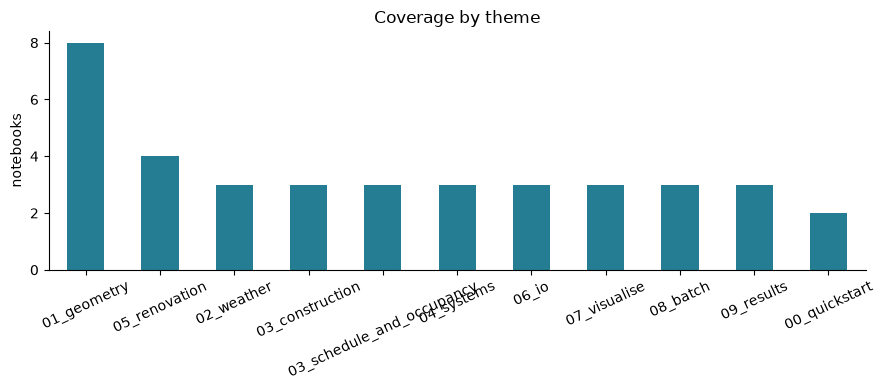

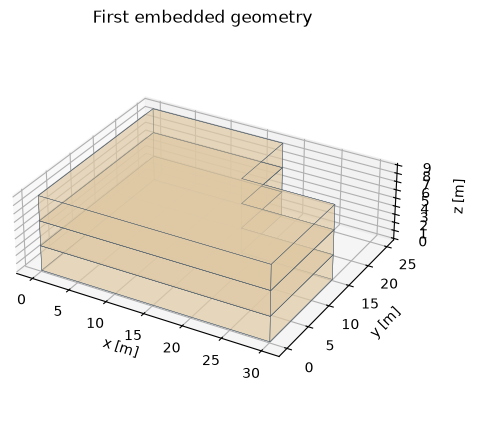

In [4]:
catalog = json.loads((ROOT / "demo/catalogue.json").read_text())
frame = table(catalog)
bars(frame.path.str.split('/').str[0].value_counts().to_dict(), "notebooks", "Coverage by theme")
preview(geometry(Footprint.l_shape(30, 25, 12, 10)), "First embedded geometry", interactive = True)

## Interpretation and next experiment

Start with the first building notebook, then visit the themes where your source data has the largest uncertainty.

For a stock study, retain the inputs, provenance and acceptance decisions with every result. A successful geometry preview does not establish simulation validity or predictive accuracy. Change one assumption at a time before combining measures, and report rejected or substituted cases alongside accepted cases.